# Continuous attractor networks: rings and periodic sheets

**English adaptation of Homework 7 — Neural Computation Modelling Workshop**

Compare built-in and custom 1D/2D CANN models, track moving stimuli, and explore the supplied noise and two-bump reference exercises.

**Run:** Use Python 3.11 or 3.12, install `requirements.txt`, and run all cells. Colab: upload this notebook and requirements file, run `%pip install -r requirements.txt`, restart if requested, then run from the top. No dataset download or GPU is needed. The 64 x 64 dense 2D model uses substantial working memory (one float32 connection matrix is 64 MiB).

**Attribution:** The source combines filled-in exercises, unfinished optional templates and complete answer keys. The prepared custom classes use the source's corrected reference formula. Optional experiments are explicitly adapted from supplied answers, not claimed as independent original work. The original file is unchanged and its personal identifier is omitted.

**Outputs:** Static plots and compact sampled GIFs replace oversized embedded JavaScript animations. GIFs show selected simulation frames at a viewing speed, not a physical-time clock; the numerical simulations still use every time step.

In [1]:
from pathlib import Path
import json
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import brainpy as bp
import brainpy.math as bm
import jax
from canns.models.basic.cann import CANN1D, CANN2D
from canns.task.tracking import SmoothTracking1D, SmoothTracking2D, TemplateMatching1D

DT = 0.1
SEED = 42
bm.set_dt(DT)
bm.random.seed(SEED)
np.random.seed(SEED)
PARAMS = dict(tau=1.0,k=8.1,a=0.5,A=10.,J0=4.,z_min=-np.pi,z_max=np.pi)
FIGURES=Path('figures');RESULTS=Path('results')
FIGURES.mkdir(exist_ok=True);RESULTS.mkdir(exist_ok=True)
versions={p:importlib.metadata.version(p) for p in ['canns','brainpy','jax','numpy','matplotlib','pillow']}
print(versions)

def save_plot(name):
    plt.tight_layout();plt.savefig(FIGURES/f'{name}.png',dpi=150);plt.show();plt.close()

def run_tracking(network,task):
    task.get_data()
    def step(t,stimulus):
        network(stimulus)
        return network.r.value,network.u.value
    rates,activity=bm.for_loop(step,(task.run_steps,task.data),progress_bar=False)
    rates,activity=np.asarray(rates),np.asarray(activity)
    assert np.isfinite(rates).all() and np.isfinite(activity).all()
    assert np.all(rates>=0)
    assert np.all(rates.reshape(len(rates),-1).sum(axis=1) <= 1/network.k+1e-6)
    return rates,activity

def line_gif(name,x,series,title,frames=60):
    indices=np.unique(np.linspace(0,len(next(iter(series.values())))-1,frames).astype(int))
    fig,ax=plt.subplots(figsize=(7,4))
    lines={label:ax.plot(x,values[0],label=label)[0] for label,values in series.items()}
    low=min(float(np.min(v)) for v in series.values());high=max(float(np.max(v)) for v in series.values())
    ax.set(xlim=(float(x[0]),float(x[-1])),ylim=(low-.05*(high-low+1),high+.1*(high-low+1)),xlabel='Preferred position / rad',ylabel='Activity (model units)')
    ax.legend(fontsize=8)
    def draw(frame):
        for label,line in lines.items():line.set_ydata(series[label][frame])
        ax.set_title(f'{title} | sample {frame+1}')
        return list(lines.values())
    animation=FuncAnimation(fig,draw,frames=indices,blit=False)
    plt.tight_layout();animation.save(FIGURES/f'{name}.gif',writer=PillowWriter(fps=12));plt.close(fig)

{'canns': '1.5.0', 'brainpy': '2.8.2', 'jax': '0.10.2', 'numpy': '2.4.6', 'matplotlib': '3.11.2', 'pillow': '13.0.0'}


## 1. Corrected custom models

The update is $r=u^2/(1+k\sum u^2)$ followed by forward Euler integration of $\tau\dot u=-u+Jr+I$.

The Gaussian prefactor must be **outside** the exponential: $J(d)=J_0\exp[-d^2/(2a^2)]/(\sqrt{2\pi}a)$. Both learner implementations in the source placed the denominator in the exponent. The complete reference answers have the correct formula and are used here.

The 2D kernel retains the source/library's same prefactor; it is a model convention, not a claim of unit-integral 2D probability normalisation. Both axes wrap periodically. To compare directly with the library we retain its endpoint-inclusive coordinate grid; the duplicated seam means exact finite-grid translation symmetry should not be assumed.

For k>0, the rate sum is bounded by 1/k. This does not set the steady membrane-activity amplitude to 1/sqrt(k), and does not make the rate an all-or-none quantity. The stored r is evaluated before each Euler update of u, as in the source.

In [2]:
class CustomCANN1D(bp.DynamicalSystem):
    """Reference-answer implementation, translated and consolidated."""
    def __init__(
        self,
        num: int,
        tau: float = 1.0,
        k: float = 8.1,
        a: float = 0.5,
        A: float = 10,
        J0: float = 4.0,
        z_min: float = -bm.pi,
        z_max: float = bm.pi,
    ):
        super().__init__()
        self.tau = tau
        self.k = k
        self.a = a
        self.A = A
        self.J0 = J0
        self.z_min = z_min
        self.z_max = z_max
        self.z_range = z_max - z_min
        self.x = bm.linspace(z_min, z_max, num)
        self.rho = num / self.z_range
        self.dx = self.z_range / num
        self.conn_mat = self.make_conn()
        self.shape = (num,)
        self.r = bm.Variable(bm.zeros(num))
        self.u = bm.Variable(bm.zeros(num))
        self.inp = bm.Variable(bm.zeros(num))
    def dist(self, d):
        """Reference-answer implementation, translated and consolidated."""
        d = bm.remainder(d, self.z_range)
        d = bm.where(d > self.z_range / 2, d - self.z_range, d)
        return d
    def make_conn(self):
        """Reference-answer implementation, translated and consolidated."""
        x_left = bm.reshape(self.x, (-1, 1))
        x_right = bm.repeat(self.x.reshape((1, -1)), len(self.x), axis=0)
        d = self.dist(x_left - x_right)
        return self.J0 * bm.exp(-0.5 * bm.square(d / self.a)) / (bm.sqrt(2 * bm.pi) * self.a)
    def get_stimulus_by_pos(self, pos):
        """Reference-answer implementation, translated and consolidated."""
        return self.A * bm.exp(-0.25 * bm.square(self.dist(self.x - pos) / self.a))
    def update(self, inp):
        """Reference-answer implementation, translated and consolidated."""
        self.inp.value = inp
        r1 = bm.square(self.u.value)
        r2 = 1.0 + self.k * bm.sum(r1)
        self.r.value = r1 / r2
        I_rec = bm.dot(self.conn_mat, self.r.value)
        self.u.value += (-self.u.value + I_rec + self.inp.value) / self.tau * bm.get_dt()

In [3]:
class CustomCANN2D(bp.DynamicalSystem):
    """Reference-answer implementation, translated and consolidated."""
    def __init__(
        self,
        length: int,
        tau: float = 1.0,
        k: float = 8.1,
        a: float = 0.5,
        A: float = 10,
        J0: float = 4.0,
        z_min: float = -bm.pi,
        z_max: float = bm.pi,
    ):
        super().__init__()
        self.length = length
        self.tau = tau
        self.k = k
        self.a = a
        self.A = A
        self.J0 = J0
        self.z_min = z_min
        self.z_max = z_max
        self.z_range = z_max - z_min
        self.x = bm.linspace(z_min, z_max, length)
        self.rho = length / self.z_range
        self.dx = self.z_range / length
        self.conn_mat = self.make_conn()
        self.shape = (length, length)
        self.r = bm.Variable(bm.zeros((length, length)))
        self.u = bm.Variable(bm.zeros((length, length)))
        self.inp = bm.Variable(bm.zeros((length, length)))
    def dist(self, d):
        """Reference-answer implementation, translated and consolidated."""
        box_size = bm.asarray([self.z_range, self.z_range])
        d = bm.remainder(d, box_size)
        d = bm.where(d > box_size / 2, d - box_size, d)
        return d
    def make_conn(self):
        """Reference-answer implementation, translated and consolidated."""
        x1, x2 = bm.meshgrid(self.x, self.x)
        all_coords = bm.stack([x1.flatten(), x2.flatten()]).T
        @jax.vmap
        def get_conn_for_one_neuron(source_coord):
            diff_vectors = self.dist(source_coord - all_coords)
            scalar_distances = bm.linalg.norm(diff_vectors, axis=1)
            return (
                self.J0
                * bm.exp(-0.5 * bm.square(scalar_distances / self.a))
                / (bm.sqrt(2 * bm.pi) * self.a)
            )
        return get_conn_for_one_neuron(all_coords)
    def get_stimulus_by_pos(self, pos):
        """Reference-answer implementation, translated and consolidated."""
        pos = bm.asarray(pos)
        x1, x2 = bm.meshgrid(self.x, self.x)
        all_coords = bm.stack([x1.flatten(), x2.flatten()]).T
        diff_vectors = self.dist(all_coords - pos)
        scalar_distances = bm.linalg.norm(diff_vectors, axis=1)
        return (self.A * bm.exp(-0.25 * bm.square(scalar_distances / self.a))).reshape(
            self.length, self.length
        )
    def update(self, inp):
        """Reference-answer implementation, translated and consolidated."""
        self.inp.value = inp
        r1 = bm.square(self.u.value)
        r2 = 1.0 + self.k * bm.sum(r1)
        self.r.value = r1 / r2
        I_rec = (self.r.value.flatten() @ self.conn_mat).reshape((self.length, self.length))
        self.u.value += (-self.u.value + I_rec + self.inp.value) / self.tau * bm.get_dt()

## 2. One-dimensional smooth tracking

Use 512 neurons. Four control positions [0,0,pi,2pi] define **three** intervals lasting [2,20,20], totalling 42 model-time units and 420 steps. The last two intervals have equal speeds in this configuration; they are not a slow/fast comparison. On the ring, positions separated by 2pi are equivalent.

Run built-in and corrected custom models under identical task definitions and compare their whole activity traces.

1D activity shape: (420, 512) maximum built-in/custom difference: 0.0


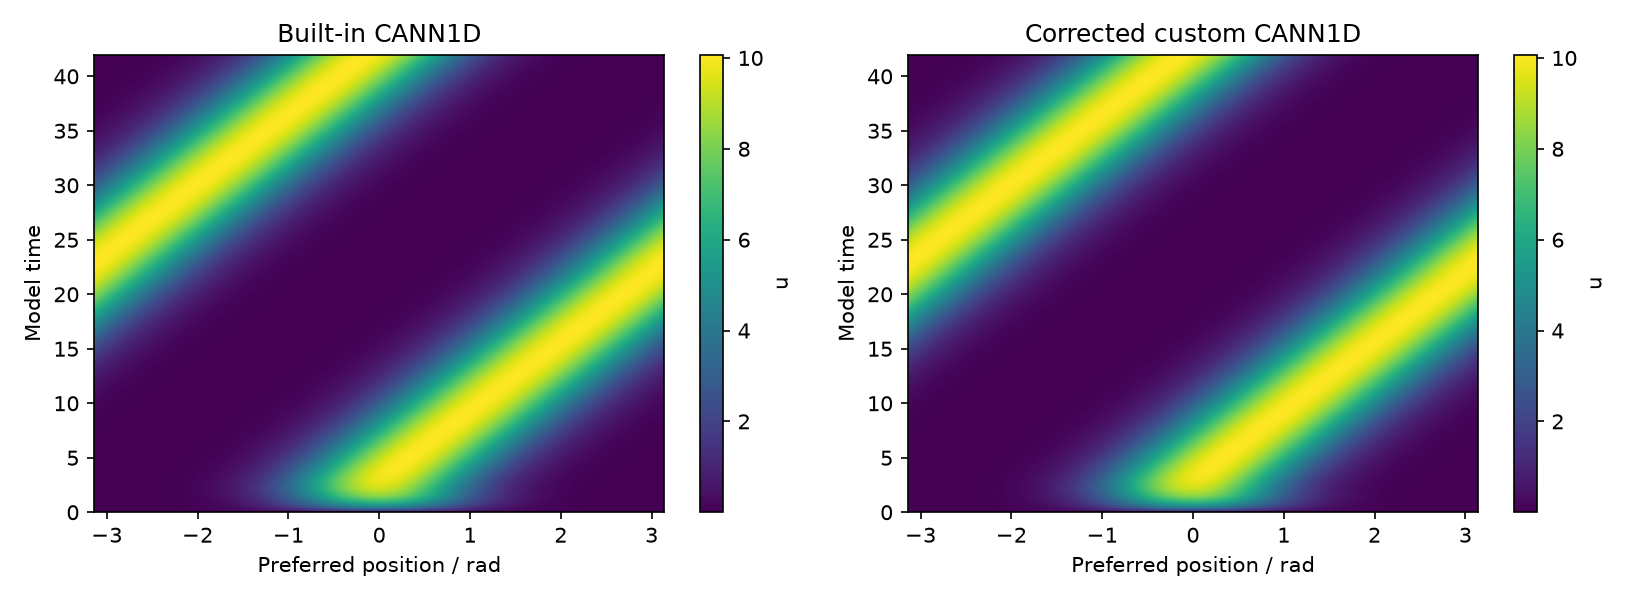

In [4]:
builtin1=CANN1D(num=512,**PARAMS)
custom1=CustomCANN1D(num=512,**PARAMS)
controls1=(0.,0.,np.pi,2*np.pi);durations1=(2.,20.,20.)
task1b=SmoothTracking1D(cann_instance=builtin1,Iext=controls1,duration=durations1,time_step=DT)
task1c=SmoothTracking1D(cann_instance=custom1,Iext=controls1,duration=durations1,time_step=DT)
r1b,u1b=run_tracking(builtin1,task1b)
r1c,u1c=run_tracking(custom1,task1c)
np.testing.assert_allclose(u1b,u1c,rtol=2e-5,atol=2e-5)
assert u1c.shape==(420,512)
print('1D activity shape:',u1c.shape,'maximum built-in/custom difference:',np.max(abs(u1b-u1c)))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,values,title in zip(axes,[u1b,u1c],['Built-in CANN1D','Corrected custom CANN1D']):
    im=ax.imshow(values,origin='lower',aspect='auto',extent=(-np.pi,np.pi,0,42),cmap='viridis')
    ax.set(xlabel='Preferred position / rad',ylabel='Model time',title=title)
    fig.colorbar(im,ax=ax,label='u')
save_plot('tracking_1d')
line_gif('tracking_1d',np.asarray(custom1.x),{'Built-in u':u1b,'Custom u':u1c,'Stimulus':np.asarray(task1c.data)},'1D smooth tracking')

## 3. Two-dimensional smooth tracking

Use a 64 x 64 periodic grid and the learner section's six control positions [(0,0),(0,0),(1,1),(0.75,0.75),(2,2),(0.75,0.75)] with five durations [10,10,10,20,10]. This totals 60 model-time units and 600 updates. The duplicate answer-key section uses a shorter path; it is not mixed into this comparison.

These plots show activity on a periodic coordinate sheet, not an independently computed energy function or a proof of an attractor manifold.

2D activity shape: (600, 64, 64) maximum built-in/custom difference: 9.536743e-07


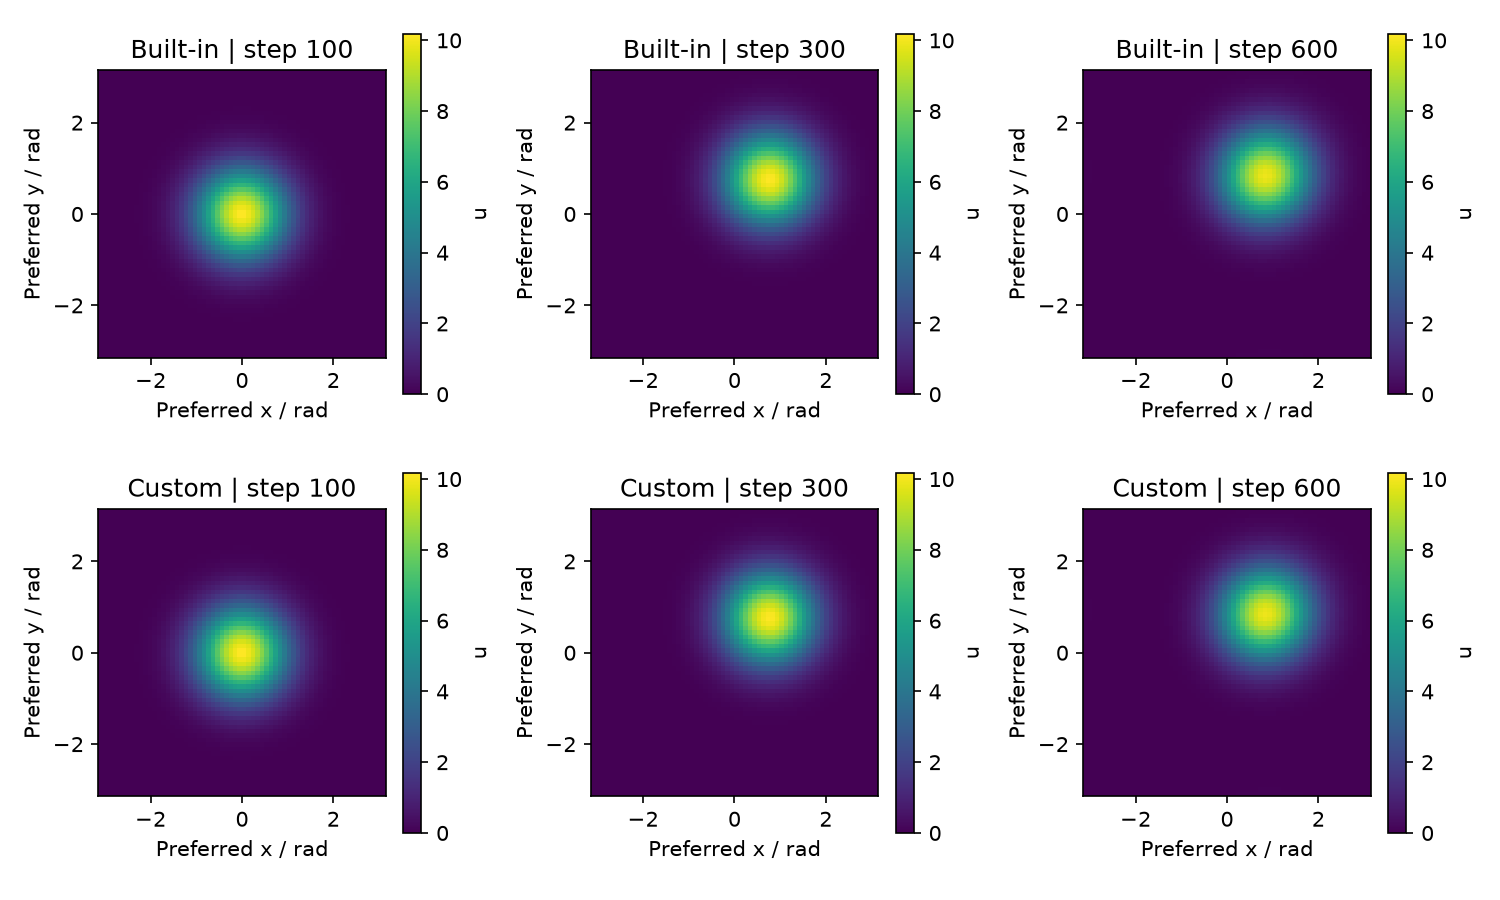

In [5]:
builtin2=CANN2D(length=64,**PARAMS)
custom2=CustomCANN2D(length=64,**PARAMS)
controls2=([0.,0.],[0.,0.],[1.,1.],[.75,.75],[2.,2.],[.75,.75])
durations2=(10.,10.,10.,20.,10.)
task2b=SmoothTracking2D(cann_instance=builtin2,Iext=controls2,duration=durations2,time_step=DT)
task2c=SmoothTracking2D(cann_instance=custom2,Iext=controls2,duration=durations2,time_step=DT)
r2b,u2b=run_tracking(builtin2,task2b)
r2c,u2c=run_tracking(custom2,task2c)
np.testing.assert_allclose(u2b,u2c,rtol=3e-5,atol=3e-5)
assert u2c.shape==(600,64,64)
print('2D activity shape:',u2c.shape,'maximum built-in/custom difference:',np.max(abs(u2b-u2c)))
fig,axes=plt.subplots(2,3,figsize=(10,6))
for row,values in enumerate([u2b,u2c]):
    for col,frame in enumerate([99,299,599]):
        ax=axes[row,col]
        im=ax.imshow(values[frame],origin='lower',extent=(-np.pi,np.pi,-np.pi,np.pi),vmin=0,vmax=float(u2b.max()))
        ax.set_title(f'{["Built-in","Custom"][row]} | step {frame+1}')
        ax.set(xlabel='Preferred x / rad',ylabel='Preferred y / rad')
        fig.colorbar(im,ax=ax,label='u')
save_plot('tracking_2d_snapshots')
fig,axes=plt.subplots(1,2,figsize=(8,4))
images=[]
for ax,values,title in zip(axes,[u2b,u2c],['Built-in','Corrected custom']):
    images.append(ax.imshow(values[0],origin='lower',extent=(-np.pi,np.pi,-np.pi,np.pi),vmin=0,vmax=float(u2b.max())))
    ax.set(xlabel='Preferred x / rad',ylabel='Preferred y / rad',title=title)
indices2=np.unique(np.linspace(0,599,60).astype(int))
def update_2d(frame):
    for im,values in zip(images,[u2b,u2c]):im.set_data(values[frame])
    fig.suptitle(f'2D activity comparison | step {frame+1}')
    return images
animation2=FuncAnimation(fig,update_2d,frames=indices2,blit=False)
plt.tight_layout();animation2.save(FIGURES/'tracking_2d.gif',writer=PillowWriter(fps=12));plt.close(fig)

## 4. Noisy template — supplied optional-answer adaptation

Run a 128-neuron custom network with `TemplateMatching1D` at position zero for 50 model-time units. The source describes Gaussian input noise with standard deviation 0.1A. We report the measured temporal standard deviation and compare late-run temporal fluctuations of input and u.

A smoother output alone does not establish a general denoising guarantee: the dynamical time constant itself filters fluctuations. This is one seeded illustrative experiment, not a noise-robustness benchmark.

Input temporal standard deviation: 1.0006507653508756
Late input/output temporal standard deviations: 1.0018905188147276 0.2189488410949707


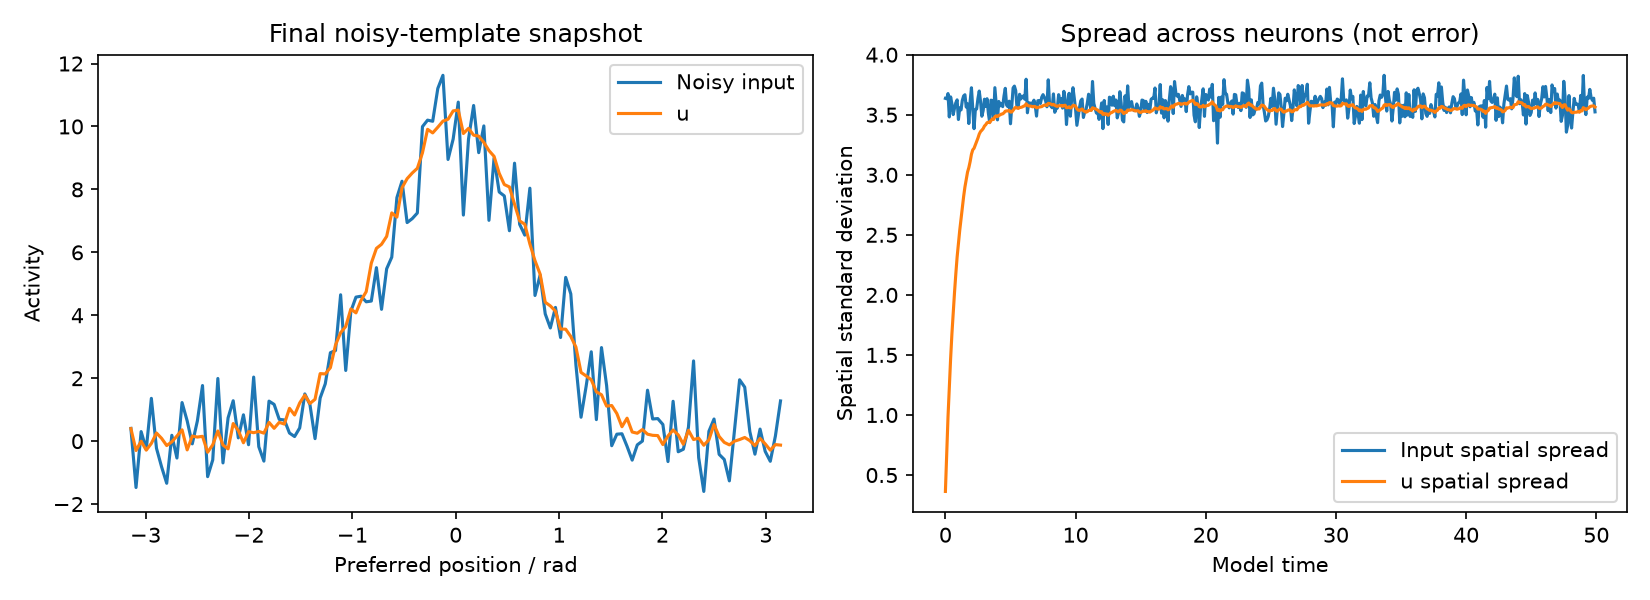

In [6]:
bm.random.seed(SEED);np.random.seed(SEED)
noise_model=CustomCANN1D(num=128,**PARAMS)
noise_task=TemplateMatching1D(cann_instance=noise_model,Iext=0.,duration=50.,time_step=DT)
r_noise,u_noise=run_tracking(noise_model,noise_task)
noisy=np.asarray(noise_task.data)
assert u_noise.shape==(500,128)
noise_std=float(noisy.std(axis=0).mean())
input_late_std=float(noisy[250:].std(axis=0).mean())
output_late_std=float(u_noise[250:].std(axis=0).mean())
print('Input temporal standard deviation:',noise_std)
print('Late input/output temporal standard deviations:',input_late_std,output_late_std)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(np.asarray(noise_model.x),noisy[-1],label='Noisy input')
axes[0].plot(np.asarray(noise_model.x),u_noise[-1],label='u')
axes[0].set(xlabel='Preferred position / rad',ylabel='Activity',title='Final noisy-template snapshot');axes[0].legend()
axes[1].plot(np.arange(500)*DT,noisy.std(axis=1),label='Input spatial spread')
axes[1].plot(np.arange(500)*DT,u_noise.std(axis=1),label='u spatial spread')
axes[1].set(xlabel='Model time',ylabel='Spatial standard deviation',title='Spread across neurons (not error)');axes[1].legend()
save_plot('noisy_template')
line_gif('noisy_template',np.asarray(noise_model.x),{'Noisy input':noisy,'u':u_noise},'Noisy template')

## 5. Two initial bumps — supplied optional-answer adaptation

Initialise a 256-neuron network with two Gaussians centred at -pi/4 and pi/4, each with amplitude 0.3. Evolve without external input for 200 model-time units. The outcome is measured rather than assumed to be merging or winner-take-all behaviour.

The source's claim that the steady u amplitude is approximately 1/sqrt(k) does not follow from divisive rate normalisation. We retain 0.3 as an exercise initial condition, not a derived steady-state amplitude. Initial r is synchronised for clarity, although this update recalculates it from u before using it.

Initial/final peak u: 0.302234947681427 0.26956862211227417


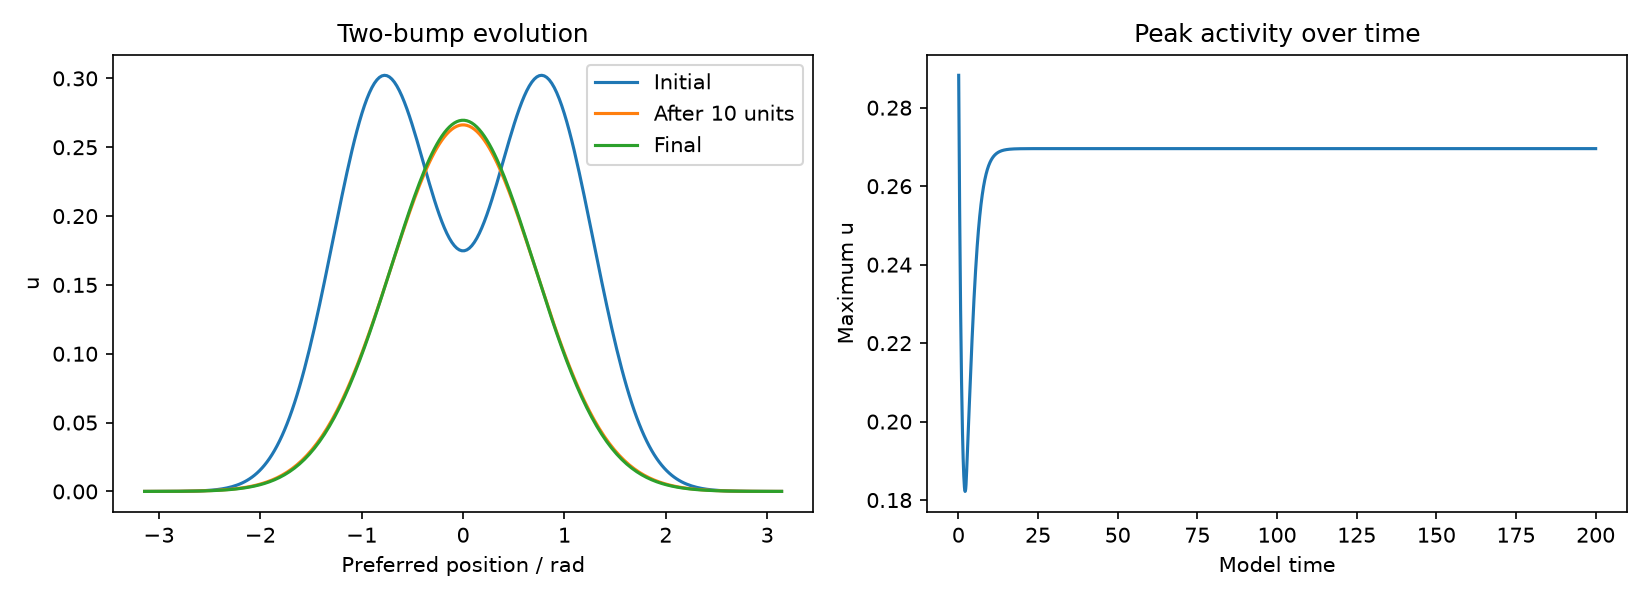

In [7]:
multi=CustomCANN1D(num=256,**PARAMS)
initial=.3*bm.exp(-.5*bm.square(multi.dist(multi.x+np.pi/4)/multi.a)) + .3*bm.exp(-.5*bm.square(multi.dist(multi.x-np.pi/4)/multi.a))
multi.u.value=initial
multi.r.value=bm.square(initial)/(1+multi.k*bm.sum(bm.square(initial)))
u_initial=np.asarray(initial).copy()
def step_multi(i,stimulus):
    multi(stimulus)
    return multi.u.value
u_multi=np.asarray(bm.for_loop(step_multi,(bm.arange(2000),bm.zeros((2000,256))),progress_bar=False))
assert u_multi.shape==(2000,256) and np.isfinite(u_multi).all()
print('Initial/final peak u:',float(u_initial.max()),float(u_multi[-1].max()))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for label,values in [('Initial',u_initial),('After 10 units',u_multi[99]),('Final',u_multi[-1])]:axes[0].plot(np.asarray(multi.x),values,label=label)
axes[0].set(xlabel='Preferred position / rad',ylabel='u',title='Two-bump evolution');axes[0].legend()
axes[1].plot((np.arange(2000)+1)*DT,u_multi.max(axis=1))
axes[1].set(xlabel='Model time',ylabel='Maximum u',title='Peak activity over time')
save_plot('two_bump_evolution')
line_gif('two_bump_evolution',np.asarray(multi.x),{'u':np.vstack([u_initial,u_multi])},'Two-bump free evolution')

## 6. Checks and limitations

Check the corrected Gaussian formula, matrix symmetry, wrapped stimulus invariance, finite trajectories, rate bounds and agreement with the built-in models. These are implementation checks, not a proof of continuous attractor stability, a time-step convergence study or biological validation.

Parameter sweeps, multiple noise seeds and alternative topology were suggested in the source but are not completed experiments here. A sphere S2 is a two-dimensional surface embedded in three dimensions. Ring/sheet models are modelling hypotheses, not one-to-one identifications with particular cell types.

In [8]:
for network in [custom1,custom2]:
    matrix=np.asarray(network.conn_mat)
    np.testing.assert_allclose(matrix,matrix.T,atol=1e-6,rtol=1e-6)
    np.testing.assert_allclose(np.diag(matrix),network.J0/(np.sqrt(2*np.pi)*network.a),atol=1e-6,rtol=1e-6)
np.testing.assert_allclose(np.asarray(custom1.get_stimulus_by_pos(0.)),np.asarray(custom1.get_stimulus_by_pos(2*np.pi)),atol=1e-4,rtol=1e-4)
np.testing.assert_allclose(np.asarray(custom2.get_stimulus_by_pos([0.,0.])),np.asarray(custom2.get_stimulus_by_pos([2*np.pi,2*np.pi])),atol=1e-4,rtol=1e-4)
summary={'seed':SEED,'dt':DT,'versions':versions,'parameters':PARAMS,
         'one_dimensional_shape':list(u1c.shape),'two_dimensional_shape':list(u2c.shape),
         'max_1d_builtin_custom_error':float(np.max(abs(u1b-u1c))),
         'max_2d_builtin_custom_error':float(np.max(abs(u2b-u2c))),
         'noise_input_temporal_std':noise_std,'late_input_temporal_std':input_late_std,
         'late_output_temporal_std':output_late_std,'two_bump_initial_peak':float(u_initial.max()),
         'two_bump_final_peak':float(u_multi[-1].max()),'one_dimensional_durations':durations1,'two_dimensional_durations':durations2}
(RESULTS/'analysis_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
np.savetxt(RESULTS/'two_bump_peak.csv',np.column_stack([(np.arange(2000)+1)*DT,u_multi.max(axis=1)]),delimiter=',',header='model_time,peak_u',comments='')
np.savetxt(RESULTS/'final_noise_profiles.csv',np.column_stack([np.asarray(noise_model.x),noisy[-1],u_noise[-1]]),delimiter=',',header='position,noisy_input,u',comments='')
# Export only sampled snapshots to keep the repository compact.
np.savez_compressed(RESULTS/'activity_snapshots.npz',x1=np.asarray(custom1.x),u1=u1c[::20],
                    x2=np.asarray(custom2.x),u2=u2c[indices2],indices2=indices2,
                    multi_x=np.asarray(multi.x),multi_initial=u_initial,multi_final=u_multi[-1])
print('All consistency checks passed.')

All consistency checks passed.
